In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [215]:
customers = pd.read_csv("olist_customers_dataset.csv")
orders = pd.read_csv('olist_orders_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
geolocation = pd.read_csv('olist_geolocation_dataset.csv')



In [5]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
customers.shape

(99441, 5)

In [8]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [9]:
customers.describe(include="all")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441.000000,99441,99441
unique,99441,96096,NaN,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,NaN,sao paulo,SP
freq,1,17,NaN,15540,41746
mean,NaN,NaN,35137.474583,NaN,NaN
std,NaN,NaN,29797.938996,NaN,NaN
min,NaN,NaN,1003.000000,NaN,NaN
25%,NaN,NaN,11347.000000,NaN,NaN
50%,NaN,NaN,24416.000000,NaN,NaN
75%,NaN,NaN,58900.000000,NaN,NaN


In [ ]:
customers['customer_city'].duplicated().any()


np.True_

In [ ]:

customers['customer_id'].duplicated().any()

np.False_

In [16]:
customers['customer_unique_id'].duplicated().any()


np.True_

In [17]:

customers['customer_zip_code_prefix'].duplicated().any()


np.True_

In [18]:
customers['customer_state'].duplicated().any()

np.True_

In [19]:
customers['customer_unique_id'].duplicated().sum()

np.int64(3345)

In [25]:
customers['customer_unique_id'].value_counts().head(1)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
Name: count, dtype: int64

In [23]:
customers['customer_unique_id'].nunique()

96096

In [26]:
(customers['customer_unique_id'].value_counts() > 1).sum()

np.int64(2997)

In [37]:
state_counts = customers.groupby('customer_state')['customer_unique_id'].nunique()
print(state_counts)

customer_state
AC       77
AL      401
AM      143
AP       67
BA     3277
CE     1313
DF     2075
ES     1964
GO     1952
MA      726
MG    11259
MS      694
MT      876
PA      949
PB      519
PE     1609
PI      482
PR     4882
RJ    12384
RN      474
RO      240
RR       45
RS     5277
SC     3534
SE      342
SP    40302
TO      273
Name: customer_unique_id, dtype: int64


In [38]:
state_counts.sort_values(ascending=False).head(5)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
Name: customer_unique_id, dtype: int64

In [35]:
customers.groupby('customer_city')['customer_unique_id'].nunique().sort_values(ascending=False).head(1)

customer_city
sao paulo    14984
Name: customer_unique_id, dtype: int64

In [53]:
max_state = state_counts.max()
total = state_counts.sum()
print(max_state/total*100)

41.92186069734542


In [43]:
min_state = state_counts.min()
print(max_state-min_state)

40257


Диаграмма

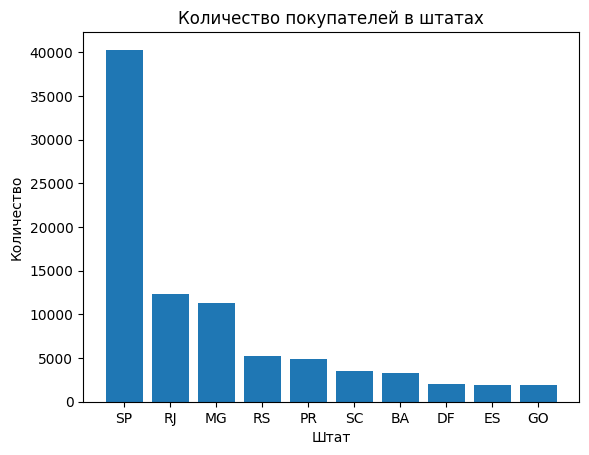

In [54]:
top10_state = state_counts.sort_values(ascending=False).head(10)
plt.bar(top10_state.index, top10_state.values)
plt.title('Количество покупателей в штатах')
plt.xlabel('Штат')
plt.ylabel('Количество')

plt.show()

In [58]:
user_states = customers.groupby('customer_unique_id')['customer_state'].nunique()
print(user_states[user_states > 1].count())

39


In [59]:
state_counts.sum()

np.int64(96136)

In [69]:
user_states = customers.groupby('customer_unique_id')['customer_state'].nunique().loc[lambda x: x>1].index
multi_states = customers[customers['customer_unique_id'].isin(user_states)]
print(multi_states.sort_values(by = 'customer_unique_id').head(15))

                            customer_id                customer_unique_id  \
70843  36d63113a38882f3f464f8eaa96c4b1c  1f90117a847636892e3c5bf569f2ac68   
47053  b0a9bd08e4116c3fdd62aebc51031f19  1f90117a847636892e3c5bf569f2ac68   
46243  1aff35540649a1c5ed033773c3585d7b  2410195f6521688005612363835a2671   
87584  a36b51ac1817af488ecb95f6e8247cfb  2410195f6521688005612363835a2671   
54225  4b9a9a8f782e51945f239d38303a0d5a  2c45ab66a3dae52960147e76a35740ff   
56186  6b6659a060f8afbe76a660d091ebb6bf  2c45ab66a3dae52960147e76a35740ff   
93312  bd63d147fd1e90cacffad1fe807d8911  2c6a91479a7dc00d8c9d650d8dee88ca   
72986  b1ff51bd725d9c52689b0cde47656bcd  2c6a91479a7dc00d8c9d650d8dee88ca   
99182  bafd51862cb88bd42d499170c2ac35fd  408aee96c75632a92e5079eee61da399   
74055  b90967a09edc5a1bbb7eff576bb6955b  408aee96c75632a92e5079eee61da399   
42677  bad4461ca80fdc3b1cbcdeb8ccb6ad42  5192c897072033288df55bd01b0e5737   
16095  2b60fa486873939bde1170b15b8ac6ac  5192c897072033288df55bd01b0e5737   

In [72]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [73]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [75]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [76]:
orders.describe(include="all")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,NaN,NaN,NaN,NaN,NaN
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,NaN,NaN,NaN,NaN,NaN
freq,1,1,96478,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111
min,NaN,NaN,NaN,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,NaN,NaN,NaN,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00
50%,NaN,NaN,NaN,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00
75%,NaN,NaN,NaN,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00
max,NaN,NaN,NaN,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [ ]:
orders_status =  orders['order_status'].unique()
print(orders_status)

<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str


In [85]:
orders_status = orders.groupby('order_status')['order_id'].count()
print(orders_status)

order_status
approved           2
canceled         625
created            5
delivered      96478
invoiced         314
processing       301
shipped         1107
unavailable      609
Name: order_id, dtype: int64


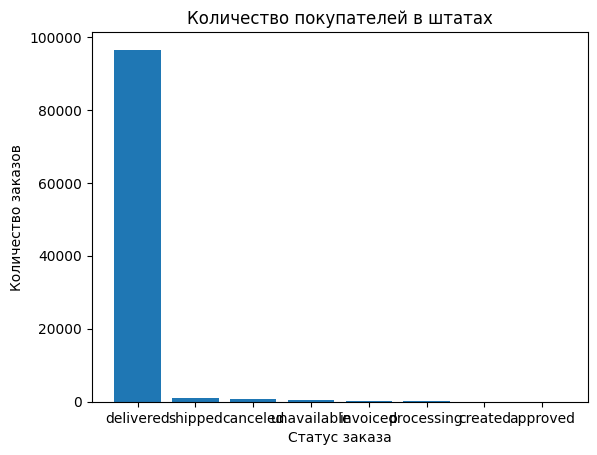

In [ ]:
orders_status = orders_status.sort_values(ascending=False)
plt.bar(orders_status.index, orders_status.values)
plt.title('Количество заказов на каждый статус')
plt.xlabel('Статус заказа')
plt.ylabel('Количество заказов')

plt.show()

In [90]:
orders_status = orders.groupby('order_status')['order_delivered_customer_date'].count()
print(orders_status)

order_status
approved           0
canceled           6
created            0
delivered      96470
invoiced           0
processing         0
shipped            0
unavailable        0
Name: order_delivered_customer_date, dtype: int64


In [91]:
mask = (orders['order_status'] == 'canceled') & (orders['order_delivered_customer_date'].notna())

# 2. Применяем фильтр к датафрейму
suspicious_orders = orders[mask]

# 3. Выбираем только нужные столбцы для наглядности
date_columns = [
    'order_id',
    'order_status',
    'order_purchase_timestamp',       # Дата покупки
    'order_approved_at',              # Дата подтверждения оплаты
    'order_delivered_carrier_date',   # Дата передачи перевозчику
    'order_delivered_customer_date',  # Дата доставки клиенту (та самая "ошибочная")
    'order_estimated_delivery_date'   # Ожидаемая дата доставки
]

# 4. Выводим результат
result = suspicious_orders[date_columns]

# Если вы работаете в Jupyter Notebook, просто напишите:
display(result) 

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09
8791,dabf2b0e35b423f94618bf965fcb7514,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30
58266,770d331c84e5b214bd9dc70a10b829d0,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29
59332,8beb59392e21af5eb9547ae1a9938d06,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30
92636,65d1e226dfaeb8cdc42f665422522d14,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08


In [ ]:
mask = (orders['order_estimated_delivery_date'] < orders['order_delivered_customer_date']) & (orders['order_status'] == 'delivered')
delay_orders = orders[mask]
display(delay_orders.shape)

(7826, 8)

In [100]:
mask = (orders['order_estimated_delivery_date'] >= orders['order_delivered_customer_date']) & (orders['order_status'] == 'delivered')
promptly_orders = orders[mask]
display(promptly_orders.shape)

(88644, 8)

In [104]:
delivered_orders = orders[(orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].notna()]
display(delivered_orders.shape)

(96470, 8)

In [106]:
display(len(delay_orders)/len(delivered_orders)*100)

8.112366538820359

In [111]:
delay_orders['delay'] = (delay_orders['order_delivered_customer_date'] - delay_orders['order_estimated_delivery_date'])
avg_delay = delay_orders['delay'].mean()
display(avg_delay.days)

9

In [112]:
max_delay = delay_orders['delay'].max()
display(max_delay)

Timedelta('188 days 23:24:07')

In [115]:
reviews.shape

(99224, 7)

In [116]:
reviews.describe(include="all")

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.000000,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,c444278834184f72b1484dfe47de7f97,c88b1d1b157a9999ce368f218a407141,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.086421,NaN,NaN,NaN,NaN
std,NaN,NaN,1.347579,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN


In [119]:
delay_orders.sort_values(by='delay', ascending=False).head(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delay
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,188 days 23:24:07
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,181 days 14:36:39
11399,47b40429ed8cce3aee9199792275433f,cb2caaaead400c97350c37a3fc536867,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,175 days 20:51:31
81401,2fe324febf907e3ea3f2aa9650869fa5,65b14237885b3972ebec28c0f7dd2220,delivered,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,167 days 17:00:07
89130,285ab9426d6982034523a855f55a885e,9cf2c3fa2632cee748e1a59ca9d09b21,delivered,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,166 days 14:00:04
61610,440d0d17af552815d15a9e41abe49359,7815125148cfa1e8c7fee1ff7974f16c,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,165 days 15:12:50
68769,c27815f7e3dd0b926b58552628481575,f85e9ec0719b16dc4dd0edd438793553,delivered,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,162 days 17:14:25
40847,d24e8541128cea179a11a65176e0a96f,beeda72b31be3b8a38b5c2b77d7705c4,delivered,2017-06-12 13:14:11,2017-06-12 13:25:11,2017-06-16 14:44:37,2017-12-04 18:36:29,2017-06-26,161 days 18:36:29
38509,0f4519c5f1c541ddec9f21b3bddd533a,1a8a4a30dc296976717f44e7801fdeef,delivered,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,161 days 14:38:21
54480,2d7561026d542c8dbd8f0daeadf67a43,8199345f57c6d1cbe9701f92481beb8d,delivered,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,159 days 14:38:18


In [145]:
delivered_orders['delay_days'] = (
    delivered_orders['order_delivered_customer_date'] - 
    delivered_orders['order_estimated_delivery_date']
).dt.days

delivered_orders['year-month'] = delivered_orders['order_purchase_timestamp'].dt.to_period('M')

delivered_orders['is_delayed'] = delivered_orders['delay_days']>0

monthly_stats = delivered_orders.groupby('year-month').agg(
    total_delivered=('order_id', 'count'),
    delayed_count=('is_delayed', 'sum'),
    avg_delay_days=('delay_days', lambda x: x[x>0].mean() if (x>0).any() else 0),
    max_delay_daus=('delay_days', lambda x: x[x > 0].max() if (x > 0).any() else 0)
).reset_index()

monthly_stats['delay_share_pct'] = np.where(
    monthly_stats['total_delivered'] > 0,
    (monthly_stats['delayed_count'] / monthly_stats['total_delivered']) * 100,
    0.0
)

monthly_stats['year-month'] = monthly_stats['year-month'].astype(str)
display(monthly_stats)



,year-month,total_delivered,delayed_count,avg_delay_days,max_delay_daus,delay_share_pct
0,2016-09,1,1,36.000000,36,100.000000
1,2016-10,265,2,9.500000,18,0.754717
2,2016-12,1,0,0.000000,0,0.000000
3,2017-01,750,22,20.227273,65,2.933333
4,2017-02,1653,49,20.795918,181,2.964307
5,2017-03,2546,116,25.431034,167,4.556167
6,2017-04,2303,151,12.337748,138,6.556665
7,2017-05,3545,106,12.537736,155,2.990127
8,2017-06,3135,95,14.263158,161,3.030303
9,2017-07,3872,108,11.685185,58,2.789256


In [136]:
len(delivered_orders)

96470

In [137]:
delivered_orders['order_id'].nunique()

96470

In [140]:
len(monthly_stats)

23

In [ ]:
monthly_stats['year-month'].nunique()

23

In [143]:
monthly_stats['year-month'].duplicated().sum()

np.int64(0)

In [144]:
delivered_orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delay_days,year-month,is_delayed
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8,2017-10,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6,2018-07,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18,2018-08,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13,2017-11,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10,2018-02,False
...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,-11,2017-03,False
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,-2,2018-02,False
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,-6,2017-08,False
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,-21,2018-01,False


In [146]:
reviews.shape

(99224, 7)

In [147]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [148]:
reviews.isna().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [149]:
reviews.duplicated().sum()

np.int64(0)

In [150]:
reviews.nunique()

review_id                  98410
order_id                   98673
review_score                   5
review_comment_title        4527
review_comment_message     36159
review_creation_date         636
review_answer_timestamp    98248
dtype: int64

In [151]:
reviews['review_id'].value_counts().head(10)

review_id
c444278834184f72b1484dfe47de7f97    3
308316408775d1600dad81bd3184556d    3
2d6ac45f859465b5c185274a1c929637    3
3415c9f764e478409e8e0660ae816dd2    3
4219a80ab469e3fc9901437b73da3f75    3
e44840754f12fad2b8646712121b349a    3
ddc52555ca27b0fe67d5255147682d2d    3
7b606b0d57b078384f0b58eac1d41d78    3
4d0e6dd087008d1f992d25ef6e1f619f    3
08528f70f579f0c830189efc523d2182    3
Name: count, dtype: int64

In [152]:
reviews['order_id'].value_counts().head(10)

order_id
c88b1d1b157a9999ce368f218a407141    3
df56136b8031ecd28e200bb18e6ddb2e    3
03c939fd7fd3b38f8485a0f95798f1f6    3
8e17072ec97ce29f0e1f111e598b0c85    3
cf73e2cb1f4a9480ed70c154da3d954a    2
169d7e0fd71d624d306f132acd791cbe    2
1c308eca3f339414a92e518e2a2e5ee9    2
2002ea16e75277eaa0b5d78632048540    2
1d297b4800ed1a3c5b0944d84c01ee99    2
0176a6846bcb3b0d3aa3116a9a768597    2
Name: count, dtype: int64

In [153]:
(reviews['order_id'].value_counts() > 1).sum()

np.int64(547)

In [154]:
duplicate_reviews = reviews[
    reviews['review_id'].duplicated(keep=False)
].sort_values('review_id')

display(duplicate_reviews.head(15))

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [155]:
duplicate_orders = reviews[
    reviews['order_id'].duplicated(keep=False)
].sort_values('order_id')

display(duplicate_orders.head(15))

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04 00:00:00,2018-03-05 17:02:00
854,830636803620cdf8b6ffaf1b2f6e92b2,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,d8e8c42271c8fb67b9dad95d98c8ff80,0176a6846bcb3b0d3aa3116a9a768597,5,NaN,NaN,2017-12-30 00:00:00,2018-01-02 10:54:47
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29 00:00:00,2018-03-30 03:16:19
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21 00:00:00,2018-03-22 01:32:08
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,NaN,2017-07-19 00:00:00,2017-07-20 12:06:11
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,NaN,2017-07-14 00:00:00,2017-07-17 13:58:06


In [156]:
reviews.groupby('review_id')['order_id'].nunique().value_counts().sort_index()

order_id
1    97621
2      764
3       25
Name: count, dtype: int64

In [157]:
reviews.groupby('order_id')['review_id'].nunique().value_counts().sort_index()

review_id
1    98126
2      543
3        4
Name: count, dtype: int64

In [158]:
duplicate_reviews.groupby('review_id').nunique().head(10)

,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
review_id,,,,,,
00130cbe1f9d422698c812ed8ded1919,2,1,0,1,1,1
0115633a9c298b6a98bcbe4eee75345f,2,1,0,0,1,1
0174caf0ee5964646040cd94e15ac95e,2,1,0,1,1,1
017808d29fd1f942d97e50184dfb4c13,2,1,0,0,1,1
0254bd905dc677a6078990aad3331a36,2,1,0,1,1,1
0288d42bef3dfe36930740c9588a570f,2,1,0,0,1,1
02aa7f5f75e964e3c7efa59a1f515281,2,1,0,0,1,1
034528cb00b6bc981847acafbdf2ae0b,2,1,0,0,1,1
03a6a25db577d0689440933055111897,2,1,0,1,1,1


In [159]:
duplicate_orders.groupby('order_id').nunique().head(10)

,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
order_id,,,,,,
0035246a40f520710769010f752e7507,2,1,0,1,2,2
013056cfe49763c6f66bda03396c5ee3,2,2,0,0,2,2
0176a6846bcb3b0d3aa3116a9a768597,2,1,0,0,1,2
02355020fd0a40a0d56df9f6ff060413,2,2,0,2,2,2
029863af4b968de1e5d6a82782e662f5,2,2,0,0,2,2
02e0b68852217f5715fb9cc885829454,2,1,0,2,2,2
02e723e8edb4a123d414f56cc9c4665e,2,1,0,1,2,2
03515a836bb855b03f7df9dee520a8fc,2,1,0,0,2,2
03c939fd7fd3b38f8485a0f95798f1f6,3,2,0,2,3,3


In [160]:
reviews['review_score'].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [ ]:
reviews[['review_creation_date', 'review_answer_timestamp']].dtypes


In [162]:
date_cols = ['review_creation_date', 'review_answer_timestamp']
for col in date_cols:
    reviews[col] = pd.to_datetime(reviews[col])
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  str           
 4   review_comment_message   40977 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 5.3 MB


In [163]:
reviews[['review_creation_date', 'review_answer_timestamp']].agg(['min', 'max'])

,review_creation_date,review_answer_timestamp
min,2016-10-02,2016-10-07 18:32:28
max,2018-08-31,2018-10-29 12:27:35


In [164]:
reviews['response_time_hours'] = reviews['review_answer_timestamp']-reviews['review_creation_date']
reviews.describe(include='all')

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,response_time_hours
count,99224,99224,99224.000000,11568,40977,99224,99224,99224
unique,98410,98673,NaN,4527,36159,NaN,NaN,NaN
top,c444278834184f72b1484dfe47de7f97,c88b1d1b157a9999ce368f218a407141,NaN,Recomendo,Muito bom,NaN,NaN,NaN
freq,3,3,NaN,423,230,NaN,NaN,NaN
mean,NaN,NaN,4.086421,NaN,NaN,2018-01-12 20:49:23.948238,2018-01-16 00:23:56.977939,3 days 03:34:33.029700
min,NaN,NaN,1.000000,NaN,NaN,2016-10-02 00:00:00,2016-10-07 18:32:28,0 days 02:08:29
25%,NaN,NaN,4.000000,NaN,NaN,2017-09-23 00:00:00,2017-09-27 01:53:27.250000,1 days 00:07:00.750000
50%,NaN,NaN,5.000000,NaN,NaN,2018-02-02 00:00:00,2018-02-04 22:41:47.500000,1 days 16:11:55.500000
75%,NaN,NaN,5.000000,NaN,NaN,2018-05-16 00:00:00,2018-05-20 12:11:21.500000,3 days 02:29:08
max,NaN,NaN,5.000000,NaN,NaN,2018-08-31 00:00:00,2018-10-29 12:27:35,518 days 16:46:52


In [165]:
reviews.sort_values(
    by='response_time_hours',
    ascending=False
)[[
    'order_id',
    'review_score',
    'review_creation_date',
    'review_answer_timestamp',
    'response_time_hours'
]].head(10)

,order_id,review_score,review_creation_date,review_answer_timestamp,response_time_hours
41620,bb5849f8ba21da43ffa31ea52ba81b37,1,2017-03-24,2018-08-24 16:46:52,518 days 16:46:52
66672,a8a2941e92152e0edc39bb862cd6b6e2,5,2017-02-14,2018-07-11 15:47:37,512 days 15:47:37
22059,898ded7ecb1e4d92997856bd8b7a8aa1,5,2017-03-28,2018-08-18 01:36:09,508 days 01:36:09
8758,3d80d12c0beadfcdcf2b4df407112f3f,4,2017-05-17,2018-08-31 16:19:53,471 days 16:19:53
13920,3b39d2ddd9066f382c924cc2c51dc584,5,2017-06-14,2018-09-03 20:51:34,446 days 20:51:34
90778,2f4b5984b0c48fc5bf385ed7f51051ca,5,2017-04-28,2018-07-05 23:30:57,433 days 23:30:57
50957,158745a153fbab78119f6c57c38c5306,4,2017-05-10,2018-06-26 12:30:15,412 days 12:30:15
39291,c0086672990e6dae8d6be4ccb38ab854,5,2017-06-29,2018-08-14 10:39:13,411 days 10:39:13
56047,365a8708db2878154916b372f72e17ef,5,2017-05-16,2018-06-03 10:20:11,383 days 10:20:11
8441,b1bb317f7d7fdeefca25499d3e62cb48,4,2017-04-05,2018-04-07 16:21:56,367 days 16:21:56


In [167]:
bins = [-1, 24, 72, 168, 720, 8760, float('inf')]

labels = [
    'До 1 дня',
    '1–3 дня',
    '3–7 дней',
    '7–30 дней',
    '30 дней – 1 год',
    'Более 1 года'
]

reviews['response_hours'] = reviews['response_time_hours'].dt.total_seconds() / 3600

reviews['response_group'] = pd.cut(
    reviews['response_hours'],
    bins=bins,
    labels=labels
)

response_distribution = reviews['response_group'].value_counts().sort_index().to_frame('count')

response_distribution['share_pct'] = (
    response_distribution['count'] / len(reviews) * 100
).round(2)

display(response_distribution)

,count,share_pct
response_group,,
До 1 дня,24361,24.55
1–3 дня,46893,47.26
3–7 дней,23056,23.24
7–30 дней,4232,4.27
30 дней – 1 год,672,0.68
Более 1 года,10,0.01


In [168]:
(reviews['response_time_hours'] < pd.Timedelta(0)).sum()

np.int64(0)

In [170]:
order_items.shape

(112650, 7)

In [171]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [172]:
order_items.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [173]:
order_items.duplicated().sum()

np.int64(0)

In [174]:
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])

In [175]:
print('Уникальных заказов:', order_items['order_id'].nunique())
print('Уникальных товаров:', order_items['product_id'].nunique())
print('Уникальных продавцов:', order_items['seller_id'].nunique())
print('Уникальных номеров позиций:', order_items['order_item_id'].nunique())

Уникальных заказов: 98666
Уникальных товаров: 32951
Уникальных продавцов: 3095
Уникальных номеров позиций: 21


In [176]:
order_items['order_item_id'].value_counts().sort_index()

order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64

In [177]:
order_items.groupby('order_id')['order_item_id'].max().value_counts().sort_index()

order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [179]:
order_items.groupby('order_id')['order_item_id'].nunique().equals(
    order_items.groupby('order_id')['order_item_id'].max()
)

True

In [180]:
order_items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [181]:
print('Товаров с нулевой ценой:', (order_items['price'] == 0).sum())
print('Товаров с нулевой доставкой:', (order_items['freight_value'] == 0).sum())
print('Товаров с отрицательной ценой:', (order_items['price'] < 0).sum())
print('Товаров с отрицательной доставкой:', (order_items['freight_value'] < 0).sum())

Товаров с нулевой ценой: 0
Товаров с нулевой доставкой: 383
Товаров с отрицательной ценой: 0
Товаров с отрицательной доставкой: 0


In [182]:
order_items[['price', 'freight_value']].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [183]:
order_items.sort_values(
    by='price',
    ascending=False
)[[
    'order_id',
    'product_id',
    'seller_id',
    'price',
    'freight_value'
]].head(10)

,order_id,product_id,seller_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,3999.90,17.01


In [184]:
order_items['total_item_value'] = (
    order_items['price'] + order_items['freight_value']
)

order_items[['price', 'freight_value', 'total_item_value']].mean()

price               120.653739
freight_value        19.990320
total_item_value    140.644059
dtype: float64

In [185]:
order_items['freight_value'].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
50%          16.260000
75%          21.150000
90%          34.041000
95%          45.120000
99%          84.520000
max         409.680000
Name: freight_value, dtype: float64

In [186]:
order_items.nlargest(10, 'freight_value')[
    ['order_id', 'product_id', 'seller_id', 'price', 'freight_value']
]

,order_id,product_id,seller_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,1045.00,314.40


In [187]:
order_items.groupby(
    ['product_id', 'seller_id']
).agg(
    orders_count=('order_id', 'nunique'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean'),
    max_freight=('freight_value', 'max')
).sort_values('max_freight', ascending=False).head(10)

,,orders_count,avg_price,avg_freight,max_freight
product_id,seller_id,,,,
ec31d2a17b299511e7c8627be9337b9b,257e61d3251fb5efb9daadddbc2cf7ca,1,979.000000,409.680000,409.68
a3cd9517ebf5a50dca25acce54f3b171,6fa9202c10491e472dffd59a3e82b2a3,3,2338.080000,308.336667,375.28
256a9c364b75753b97bee410c9491ad8,5c030029b5916fed0986310385ec9009,1,1149.000000,339.590000,339.59
97c948ebc8c04b26b7bbb095d4228f2a,17f51e7198701186712e53a39c564617,5,1050.000000,246.666000,338.30
46e24ce614899e36617e37ea1e4aa6ff,17f51e7198701186712e53a39c564617,2,1050.000000,253.805000,321.88
363a9f5b97bf194da23858be722a7aa5,9596c870880d900012f2e8e6e30d06d7,3,1026.666667,271.266667,321.46
7e53e051875b2a0c9f22acd8a9a29a20,eeb6de78f79159600292e314a77cbd18,1,3089.000000,317.470000,317.47
dc861f18267cce21f3b70f9f7990b8ce,17f51e7198701186712e53a39c564617,2,990.000000,207.350000,314.02
1d16c0509e7011656e03c6a582ff6667,17f51e7198701186712e53a39c564617,6,760.000000,165.105714,312.41


In [190]:
order_payments.shape

(103886, 5)

In [191]:
order_payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [192]:
print('Пропуски:')
print(order_payments.isna().sum())

print('\nПолные дубликаты:')
print(order_payments.duplicated().sum())

print('\nКоличество уникальных значений:')
print(order_payments.nunique())

Пропуски:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Полные дубликаты:
0

Количество уникальных значений:
order_id                99440
payment_sequential         29
payment_type                5
payment_installments       24
payment_value           29077
dtype: int64


In [193]:
order_payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [194]:
order_payments['payment_type'].value_counts(normalize=True).mul(100).round(2)

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

In [195]:
payments_per_order = (
    order_payments.groupby('order_id')
    .size()
    .value_counts()
    .sort_index()
)

payments_per_order

1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64

In [196]:
order_payments.groupby('order_id')['payment_sequential'].max().value_counts().sort_index()

payment_sequential
1     96401
2      2458
3       303
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64

In [197]:
payment_check = order_payments.groupby('order_id').agg(
    rows_count=('payment_sequential', 'size'),
    sequential_count=('payment_sequential', 'nunique'),
    max_sequential=('payment_sequential', 'max')
)

payment_check[
    (payment_check['rows_count'] != payment_check['max_sequential']) |
    (payment_check['sequential_count'] != payment_check['max_sequential'])
].head(15)

,rows_count,sequential_count,max_sequential
order_id,,,
00ac05fe0fc047c54418098eb64e3aaa,1,1,2
056c68d093c100017aab1f00f260705c,1,1,2
0668d086b3ae41adde3aed3dacbc8fae,1,1,2
0a7d898c6305101e69e9f5a05cd0130d,1,1,2
0d0e88a418636d40ea780339701db49c,1,1,2
0fdb6f73fab7005c84d4a43d8a93682b,1,1,2
159da9914b51de617fe80162939965c5,1,1,2
166b01d0fce75a595b92ad9e84e0843b,1,1,2
1896e8b8fd196151559b02e31e98ce89,1,1,2


In [198]:
payment_check[
    payment_check['rows_count'] != payment_check['max_sequential']
].shape

(80, 3)

In [199]:
payment_check['max_sequential'].value_counts().sort_index()

max_sequential
1     96401
2      2458
3       303
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64

In [200]:
order_payments[
    (order_payments['payment_sequential'] == 2) &
    (order_payments['order_id'].isin(
        payment_check[
            payment_check['rows_count'] == 1
        ].index
    ))
].head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
625,900fac51d850dfc38fceb9c413441c67,2,debit_card,1,98.33
2191,510bff1cf06be1143d3b6698df2fd486,2,credit_card,8,406.38
3071,d7d9f1ff0b6aa62f2d4e7fc99e60e8ea,2,debit_card,1,35.00
3272,cfa1591318ed6c901b0c80debfd4b811,2,credit_card,10,330.11
4218,e17ed9c20d79f29256a4a514e8d07230,2,debit_card,1,118.43
4352,c3a4760791fe90fe58b360dbfc812805,2,debit_card,1,37.13
4429,9769f28d910e7304d7bf0fcd32d8ecd6,2,credit_card,4,339.54
5826,615915458e5cdf8939ae422e043ca879,2,credit_card,10,112.68
6200,f5691c2b1ca263490374d13d020bd950,2,debit_card,1,172.98
6803,497dd86000dbe348d33b6fa239f2521b,2,debit_card,1,37.26


In [201]:
order_payments['payment_installments'].value_counts().sort_index()

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [202]:
order_payments['payment_installments'].describe()

count    103886.000000
mean          2.853349
std           2.687051
min           0.000000
25%           1.000000
50%           1.000000
75%           4.000000
max          24.000000
Name: payment_installments, dtype: float64

In [203]:
order_payments[
    order_payments['payment_installments'] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


In [204]:
order_payments[
    order_payments['payment_installments'] >= 18
].sort_values('payment_installments', ascending=False)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
2970,70b7e94ea46d3e8b5bc12a50186edaf0,1,credit_card,24,274.84
12307,ff36cbc44b8f228e0449c92ef089c843,1,credit_card,24,756.49
10791,859f516f2fc3f95772e63c5757ab0d5b,1,credit_card,24,609.56
82431,1800f4a4362310d7eb38281634f6dfd1,1,credit_card,24,325.37
87593,61450e6c8f56d52e46a198e57df7d731,1,credit_card,24,252.09
...,...,...,...,...,...
71065,9d00d5c50382768149ce030b6ab28fc5,1,credit_card,18,236.04
67870,43004196fdbcc54ae90a84736bb13afe,1,credit_card,18,249.70
83730,466f73a6394012b9c7cfe801be0c04c3,1,credit_card,18,368.70
86226,bfa10a79da20194eb33afb833020e3eb,1,credit_card,18,335.89


In [205]:
order_payments['payment_value'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
90%         297.270000
95%         437.635000
99%        1039.916500
max       13664.080000
Name: payment_value, dtype: float64

In [206]:
print('Нулевые суммы:',
      (order_payments['payment_value'] == 0).sum())

print('Отрицательные суммы:',
      (order_payments['payment_value'] < 0).sum())

Нулевые суммы: 9
Отрицательные суммы: 0


In [207]:
order_payments[
    order_payments['payment_value'] == 0
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


In [208]:
order_payments.nlargest(10, 'payment_value')[
    ['order_id', 'payment_sequential', 'payment_type',
     'payment_installments', 'payment_value']
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08
34370,736e1922ae60d0d6a89247b851902527,1,boleto,1,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,1,credit_card,8,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,1,boleto,1,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,1,boleto,1,6726.66
62409,2cc9089445046817a7539d90805e6e5a,1,boleto,1,6081.54
43232,a96610ab360d42a2e5335a3998b4718a,1,credit_card,10,4950.34
70320,b4c4b76c642808cbe472a32b86cddc95,1,credit_card,5,4809.44
6440,199af31afc78c699f0dbf71fb178d4d4,1,credit_card,8,4764.34
67546,8dbc85d1447242f3b127dda390d56e19,1,credit_card,8,4681.78


In [209]:
order_items[
    order_items['order_id'] == '03caa2c082116e1d31e67e9ae3700499'
][['product_id', 'price', 'freight_value']]

,product_id,price,freight_value
1647,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1648,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1649,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1650,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1651,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1652,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1653,5769ef0a239114ac3a854af00df129e4,1680.0,28.01
1654,5769ef0a239114ac3a854af00df129e4,1680.0,28.01


In [210]:
order_payments[
    order_payments['order_id'] == '03caa2c082116e1d31e67e9ae3700499'
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,1,credit_card,1,13664.08


In [212]:
print(products.shape)
products.info()

(32951, 9)
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [213]:
print('Дубликаты product_id:', products['product_id'].duplicated().sum())

print('\nКоличество категорий:',
      products['product_category_name'].nunique())

print('\nПропуски:')
print(products.isna().sum())

numeric_cols = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

print('\nНулевые и отрицательные значения:')
print((products[numeric_cols] <= 0).sum())

Дубликаты product_id: 0

Количество категорий: 73

Пропуски:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Нулевые и отрицательные значения:
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              4
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


In [214]:
# Сколько товаров имеют пропуски в характеристиках
print('Товары с пропусками в категории:',
      products['product_category_name'].isna().sum())

# Строки с нулевым или отрицательным весом
print(products[products['product_weight_g'] <= 0][
    ['product_id', 'product_category_name', 'product_weight_g']
])

# Распределение товаров по категориям
print(products['product_category_name'].value_counts().head(10))

Товары с пропусками в категории: 610
                             product_id product_category_name  \
9769   81781c0fed9fe1ad6e8c81fca1e1cb08       cama_mesa_banho   
13683  8038040ee2a71048d4bdbbdc985b69ab       cama_mesa_banho   
14997  36ba42dd187055e1fbe943b2d11430ca       cama_mesa_banho   
32079  e673e90efa65a5409ff4196c038bb5af       cama_mesa_banho   

       product_weight_g  
9769                0.0  
13683               0.0  
14997               0.0  
32079               0.0  
product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64


In [216]:
print(sellers.shape)
sellers.info()
print('\nДубликаты seller_id:', sellers['seller_id'].duplicated().sum())
print('\nПропуски:\n', sellers.isna().sum())
print('\nКоличество уникальных продавцов:', sellers['seller_id'].nunique())
print('\nКоличество штатов:', sellers['seller_state'].nunique())
print('\nКоличество городов:', sellers['seller_city'].nunique())

(3095, 4)
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB

Дубликаты seller_id: 0

Пропуски:
 seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Количество уникальных продавцов: 3095

Количество штатов: 23

Количество городов: 611


In [217]:
print(geolocation.shape)
geolocation.info()

print('\nПропуски:\n', geolocation.isna().sum())

print('\nДубликаты строк:', geolocation.duplicated().sum())

print('\nКоличество уникальных почтовых индексов:',
      geolocation['geolocation_zip_code_prefix'].nunique())

print('\nДиапазоны координат:')
print(geolocation[['geolocation_lat', 'geolocation_lng']].describe())

(1000163, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB

Пропуски:
 geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Дубликаты строк: 261831

Количество уникальных почтовых индексов: 19015

Диапазоны координат:
       geolocation_lat  geolocation_lng
count     1.000163e+06     1.000163e+06
mean     -2.117615e+01    -4.639054e+01
st

In [218]:
print('Дубликаты order_id в orders:',
      orders['order_id'].duplicated().sum())

print('Дубликаты customer_id в orders:',
      orders['customer_id'].duplicated().sum())

print('Дубликаты customer_id в customers:',
      customers['customer_id'].duplicated().sum())

print('Заказы без соответствующего покупателя:',
      (~orders['customer_id'].isin(customers['customer_id'])).sum())

print('Покупатели без соответствующего заказа:',
      (~customers['customer_id'].isin(orders['customer_id'])).sum())

print('Заказы с несколькими отзывами:',
      (reviews.groupby('order_id').size() > 1).sum())

Дубликаты order_id в orders: 0
Дубликаты customer_id в orders: 0
Дубликаты customer_id в customers: 0
Заказы без соответствующего покупателя: 0
Покупатели без соответствующего заказа: 0
Заказы с несколькими отзывами: 547


In [219]:
main = orders.merge(
    customers[['customer_id', 'customer_unique_id',
               'customer_city', 'customer_state']],
    on='customer_id',
    how='left',
    validate='one_to_one'
)

print(main.shape)
print(main.isna().sum())
print(main.head())

(99441, 11)
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
customer_unique_id                  0
customer_city                       0
customer_state                      0
dtype: int64
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11

In [220]:
reviews_agg = (
    reviews.groupby('order_id')
    .agg(
        review_score=('review_score', 'mean'),
        review_count=('review_score', 'count')
    )
    .reset_index()
)

print('Размер таблицы:', reviews_agg.shape)
print('Дубликаты order_id:', reviews_agg['order_id'].duplicated().sum())

main = main.merge(
    reviews_agg,
    on='order_id',
    how='left',
    validate='one_to_one'
)

print('\nРазмер основной таблицы:', main.shape)
print('\nПропуски после объединения:')
print(main[['review_score', 'review_count']].isna().sum())

Размер таблицы: (98673, 3)
Дубликаты order_id: 0

Размер основной таблицы: (99441, 13)

Пропуски после объединения:
review_score    768
review_count    768
dtype: int64


In [221]:
items_agg = (
    order_items.groupby('order_id')
    .agg(
        items_count=('order_item_id', 'count'),
        product_cost=('price', 'sum'),
        freight_cost=('freight_value', 'sum')
    )
    .reset_index()
)

items_agg['order_cost'] = (
    items_agg['product_cost'] + items_agg['freight_cost']
)

print(items_agg.shape)
print(items_agg.head())

main = main.merge(
    items_agg,
    on='order_id',
    how='left',
    validate='one_to_one'
)

print('\nРазмер main:', main.shape)
print('\nПропуски:')
print(main[['items_count', 'product_cost',
            'freight_cost', 'order_cost']].isna().sum())

(98666, 5)
                           order_id  items_count  product_cost  freight_cost  \
0  00010242fe8c5a6d1ba2dd792cb16214            1         58.90         13.29   
1  00018f77f2f0320c557190d7a144bdd3            1        239.90         19.93   
2  000229ec398224ef6ca0657da4fc703e            1        199.00         17.87   
3  00024acbcdf0a6daa1e931b038114c75            1         12.99         12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9            1        199.90         18.14   

   order_cost  
0       72.19  
1      259.83  
2      216.87  
3       25.78  
4      218.04  

Размер main: (99441, 17)

Пропуски:
items_count     775
product_cost    775
freight_cost    775
order_cost      775
dtype: int64


In [222]:
payments_agg = (
    order_payments.groupby('order_id')
    .agg(
        payment_total=('payment_value', 'sum'),
        payment_records=('payment_value', 'count'),
        payment_types=('payment_type', 'nunique')
    )
    .reset_index()
)

main = main.merge(
    payments_agg,
    on='order_id',
    how='left',
    validate='one_to_one'
)

print('Размер main:', main.shape)

print('\nПропуски:')
print(main[['payment_total', 'payment_records',
            'payment_types']].isna().sum())

print('\nПервые строки:')
print(main[['order_id', 'order_cost', 'payment_total',
            'payment_records', 'payment_types']].head())

Размер main: (99441, 20)

Пропуски:
payment_total      1
payment_records    1
payment_types      1
dtype: int64

Первые строки:
                           order_id  order_cost  payment_total  \
0  e481f51cbdc54678b7cc49136f2d6af7       38.71          38.71   
1  53cdb2fc8bc7dce0b6741e2150273451      141.46         141.46   
2  47770eb9100c2d0c44946d9cf07ec65d      179.12         179.12   
3  949d5b44dbf5de918fe9c16f97b45f8a       72.20          72.20   
4  ad21c59c0840e6cb83a9ceb5573f8159       28.62          28.62   

   payment_records  payment_types  
0              3.0            2.0  
1              1.0            1.0  
2              1.0            1.0  
3              1.0            1.0  
4              1.0            1.0  


In [223]:
# Оставляем заказы, где обе суммы известны
comparison = main.dropna(
    subset=['order_cost', 'payment_total']
).copy()

# Разница между платежом и стоимостью заказа
comparison['payment_diff'] = (
    comparison['payment_total'] - comparison['order_cost']
)

print('Количество заказов для сравнения:', len(comparison))

print('\nСтатистика расхождений:')
print(comparison['payment_diff'].describe())

print('\nКоличество заказов с расхождениями больше 0.01 BRL:',
      (comparison['payment_diff'].abs() > 0.01).sum())

print('\nТоп-10 наибольших расхождений:')
print(
    comparison.loc[
        comparison['payment_diff'].abs().nlargest(10).index,
        ['order_id', 'order_cost', 'payment_total', 'payment_diff']
    ]
)

Количество заказов для сравнения: 98665

Статистика расхождений:
count    98665.000000
mean         0.029092
std          1.129221
min        -51.620000
25%          0.000000
50%          0.000000
75%          0.000000
max        182.810000
Name: payment_diff, dtype: float64

Количество заказов с расхождениями больше 0.01 BRL: 381

Топ-10 наибольших расхождений:
                               order_id  order_cost  payment_total  \
11791  ce6d150fb29ada17d2082f4847107665     1403.66        1586.47   
48686  6e5fe7366a2e1bfbf3257dba0af1267f      287.91         406.92   
70865  70b742795bc441e94a44a084b6d9ce7a      466.93         578.82   
33150  996c7e73600ad3723e8627ab7bef81e4      587.90         664.43   
52985  70b7e94ea46d3e8b5bc12a50186edaf0      213.15         274.84   
85434  bc2c82b0ef78d2252b6176d1972db7c9      242.01         303.02   
94304  af9ffff2ce6b3defd34fd4c78857a379      413.17         466.97   
31661  262118ce178bb3e4590a3adcf6d62e6b      177.74         126.12   
68811

In [224]:
# Оставляем доставленные заказы
delivered = main[main['order_status'] == 'delivered'].copy()

# Считаем количество заказов каждого покупателя
customer_orders = (
    delivered.groupby('customer_unique_id')
    .agg(
        orders_count=('order_id', 'nunique'),
        total_spent=('order_cost', 'sum')
    )
    .reset_index()
)

# Определяем повторных покупателей
customer_orders['is_repeat'] = customer_orders['orders_count'] > 1

# Общая статистика
print('Количество покупателей:', len(customer_orders))
print('Повторных покупателей:', customer_orders['is_repeat'].sum())
print('Доля повторных покупателей, %:',
      round(customer_orders['is_repeat'].mean() * 100, 2))

print('\nРаспределение по количеству заказов:')
print(customer_orders['orders_count'].value_counts().sort_index().head(10))

Количество покупателей: 93358
Повторных покупателей: 2801
Доля повторных покупателей, %: 3.0

Распределение по количеству заказов:
orders_count
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [225]:
# Средняя оценка по каждому покупателю
customer_reviews = (
    delivered.groupby('customer_unique_id')
    .agg(
        avg_review=('review_score', 'mean'),
        reviews_count=('review_score', 'count')
    )
    .reset_index()
)

# Объединяем с таблицей повторных покупок
customer_analysis = customer_orders.merge(
    customer_reviews,
    on='customer_unique_id',
    how='left',
    validate='one_to_one'
)

# Сравниваем группы
review_comparison = (
    customer_analysis.groupby('is_repeat')
    .agg(
        customers=('customer_unique_id', 'count'),
        avg_review=('avg_review', 'mean'),
        median_review=('avg_review', 'median'),
        reviews_count=('reviews_count', 'sum')
    )
    .round(2)
)

print(review_comparison)

           customers  avg_review  median_review  reviews_count
is_repeat                                                     
False          90557        4.15           5.00          89963
True            2801        4.21           4.67           5869


In [227]:
date_columns = [
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    main[col] = pd.to_datetime(main[col], errors='coerce')

In [229]:
delivery_analysis = delivered.merge(
    main[['order_id', 'order_delivered_customer_date',
          'order_estimated_delivery_date']],
    on='order_id',
    how='left',
    validate='one_to_one',
    suffixes=('', '_new')
)

In [230]:
for col in date_columns:
    delivered[col] = pd.to_datetime(delivered[col], errors='coerce')

delivery_analysis = delivered.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'review_score'
    ]
).copy()

delivery_analysis['delay_days'] = (
    delivery_analysis['order_delivered_customer_date'] -
    delivery_analysis['order_estimated_delivery_date']
).dt.total_seconds() / 86400

delivery_analysis['delivery_group'] = delivery_analysis[
    'delay_days'
].apply(lambda x: 'С опозданием' if x > 0 else 'Вовремя или раньше')

delivery_comparison = (
    delivery_analysis.groupby('delivery_group')
    .agg(
        orders=('order_id', 'count'),
        avg_review=('review_score', 'mean'),
        median_review=('review_score', 'median')
    )
    .round(2)
)

print(delivery_comparison)

                    orders  avg_review  median_review
delivery_group                                       
Вовремя или раньше   88163        4.29            5.0
С опозданием          7661        2.57            2.0


In [231]:
print('Корреляция Пирсона:')
print(delivery_analysis['delay_days'].corr(
    delivery_analysis['review_score']
))

print('\nКорреляция Спирмена:')
print(delivery_analysis['delay_days'].corr(
    delivery_analysis['review_score'],
    method='spearman'
))

Корреляция Пирсона:
-0.2669081976306702

Корреляция Спирмена:
-0.17566941207881423


In [232]:
# Добавляем категорию товара
category_analysis = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Добавляем оценки и статус заказа
category_analysis = category_analysis.merge(
    main[['order_id', 'review_score', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Оставляем доставленные заказы с оценками и известной категорией
category_analysis = category_analysis[
    (category_analysis['order_status'] == 'delivered') &
    (category_analysis['review_score'].notna()) &
    (category_analysis['product_category_name'].notna())
].copy()

# Считаем показатели по категориям
category_stats = (
    category_analysis.groupby('product_category_name')
    .agg(
        items_count=('product_id', 'count'),
        avg_review=('review_score', 'mean'),
        median_review=('review_score', 'median')
    )
    .round(2)
    .sort_values('avg_review')
)

print('Количество категорий:', len(category_stats))

print('\n10 категорий с самыми низкими оценками:')
print(category_stats.head(10))

print('\n10 категорий с самыми высокими оценками:')
print(category_stats.tail(10))

Количество категорий: 73

10 категорий с самыми низкими оценками:
                                               items_count  avg_review  \
product_category_name                                                    
seguros_e_servicos                                       2        2.50   
fraldas_higiene                                         37        3.38   
portateis_cozinha_e_preparadores_de_alimentos           14        3.43   
moveis_escritorio                                     1654        3.51   
pc_gamer                                                 8        3.62   
casa_conforto_2                                         27        3.63   
fashion_roupa_masculina                                124        3.76   
telefonia_fixa                                         252        3.76   
artigos_de_festas                                       42        3.83   
audio                                                  358        3.84   

                                             

In [234]:
# Одна строка на сочетание "заказ — категория"
order_category = (
    order_items.merge(
        products[['product_id', 'product_category_name']],
        on='product_id',
        how='left',
        validate='many_to_one'
    )
    .dropna(subset=['product_category_name'])
    .groupby(['order_id', 'product_category_name'])
    .size()
    .reset_index(name='items_count')
)

# Добавляем оценку заказа
order_category = order_category.merge(
    main[['order_id', 'review_score', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Оставляем доставленные заказы с оценками
order_category = order_category[
    (order_category['order_status'] == 'delivered') &
    (order_category['review_score'].notna())
].copy()

# Признак низкой оценки
order_category['low_review'] = (
    order_category['review_score'] <= 2
).astype(int)

# Итоговая статистика по категориям
category_stats = (
    order_category.groupby('product_category_name')
    .agg(
        orders=('order_id', 'nunique'),
        avg_review=('review_score', 'mean'),
        low_review_share=('low_review', 'mean')
    )
    .round(3)
)

# Оставляем категории минимум с 100 заказами
category_stats = category_stats[
    category_stats['orders'] >= 100
].sort_values('avg_review')

print('Категории с самыми низкими оценками:')
print(category_stats.head(10))

print('\nКатегории с самой высокой долей низких оценок:')
print(
    category_stats.sort_values(
        'low_review_share', ascending=False
    ).head(10)
)

Категории с самыми низкими оценками:
                                  orders  avg_review  low_review_share
product_category_name                                                 
moveis_escritorio                   1244       3.643             0.219
fashion_roupa_masculina              105       3.819             0.229
audio                                345       3.839             0.217
casa_conforto                        390       3.887             0.187
telefonia_fixa                       209       3.967             0.167
construcao_ferramentas_seguranca     158       3.975             0.171
casa_construcao                      481       3.985             0.173
cama_mesa_banho                     9177       3.999             0.159
fashion_underwear_e_moda_praia       116       4.009             0.164
telefonia                           4069       4.052             0.141

Категории с самой высокой долей низких оценок:
                                  orders  avg_review  low_revie

In [235]:
import numpy as np

delivery_analysis['delay_group'] = pd.cut(
    delivery_analysis['delay_days'],
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=[
        'Вовремя или раньше',
        'Опоздание до 3 дней',
        'Опоздание 3–7 дней',
        'Опоздание более 7 дней'
    ]
)

delay_comparison = (
    delivery_analysis.groupby('delay_group', observed=False)
    .agg(
        orders=('order_id', 'nunique'),
        avg_review=('review_score', 'mean'),
        low_review_share=(
            'review_score',
            lambda x: (x <= 2).mean() * 100
        )
    )
    .round(2)
)

print(delay_comparison)

                        orders  avg_review  low_review_share
delay_group                                                 
Вовремя или раньше       88163        4.29              9.19
Опоздание до 3 дней       2636        3.77             19.08
Опоздание 3–7 дней        1773        2.32             61.25
Опоздание более 7 дней    3252        1.73             78.32


In [236]:
# 1. Готовим таблицу заказов
dashboard_orders = main[
    main['order_status'] == 'delivered'
].copy()

# Преобразуем даты
dashboard_orders['order_purchase_timestamp'] = pd.to_datetime(
    dashboard_orders['order_purchase_timestamp'],
    errors='coerce'
)

dashboard_orders['order_delivered_customer_date'] = pd.to_datetime(
    dashboard_orders['order_delivered_customer_date'],
    errors='coerce'
)

dashboard_orders['order_estimated_delivery_date'] = pd.to_datetime(
    dashboard_orders['order_estimated_delivery_date'],
    errors='coerce'
)

# Рассчитываем задержку доставки
dashboard_orders['delay_days'] = (
    dashboard_orders['order_delivered_customer_date'] -
    dashboard_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Добавляем признак повторного покупателя
dashboard_orders = dashboard_orders.merge(
    customer_orders[['customer_unique_id', 'is_repeat']],
    on='customer_unique_id',
    how='left',
    validate='many_to_one'
)

# Оставляем необходимые столбцы
dashboard_orders = dashboard_orders[[
    'order_id',
    'customer_unique_id',
    'order_purchase_timestamp',
    'customer_state',
    'order_cost',
    'review_score',
    'delay_days',
    'is_repeat'
]]

# Сохраняем
dashboard_orders.to_csv(
    'dashboard_orders.csv',
    index=False,
    encoding='utf-8-sig'
)

print(dashboard_orders.shape)
print(dashboard_orders.head())

(96478, 8)
                           order_id                customer_unique_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  7c396fd4830fd04220f754e42b4e5bff   
1  53cdb2fc8bc7dce0b6741e2150273451  af07308b275d755c9edb36a90c618231   
2  47770eb9100c2d0c44946d9cf07ec65d  3a653a41f6f9fc3d2a113cf8398680e8   
3  949d5b44dbf5de918fe9c16f97b45f8a  7c142cf63193a1473d2e66489a9ae977   
4  ad21c59c0840e6cb83a9ceb5573f8159  72632f0f9dd73dfee390c9b22eb56dd6   

  order_purchase_timestamp customer_state  order_cost  review_score  \
0      2017-10-02 10:56:33             SP       38.71           4.0   
1      2018-07-24 20:41:37             BA      141.46           4.0   
2      2018-08-08 08:38:49             GO      179.12           5.0   
3      2017-11-18 19:28:06             RN       72.20           5.0   
4      2018-02-13 21:18:39             SP       28.62           5.0   

   delay_days  is_repeat  
0   -7.107488       True  
1   -5.355729      False  
2  -17.245498      False  
3  -12.980069  

In [237]:
# Месяц заказа
dashboard_orders['order_month'] = (
    dashboard_orders['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

# Группа задержки
dashboard_orders['delay_group'] = pd.cut(
    dashboard_orders['delay_days'],
    bins=[-float('inf'), 0, 3, 7, float('inf')],
    labels=[
        'Вовремя или раньше',
        'Опоздание до 3 дней',
        'Опоздание 3–7 дней',
        'Опоздание более 7 дней'
    ]
)

# Перезаписываем CSV
dashboard_orders.to_csv(
    'dashboard_orders.csv',
    index=False,
    encoding='utf-8-sig'
)

print(dashboard_orders[
    ['order_month', 'delay_group']
].head())

print('\nПропуски:')
print(dashboard_orders.isna().sum())

  order_month         delay_group
0     2017-10  Вовремя или раньше
1     2018-07  Вовремя или раньше
2     2018-08  Вовремя или раньше
3     2017-11  Вовремя или раньше
4     2018-02  Вовремя или раньше

Пропуски:
order_id                      0
customer_unique_id            0
order_purchase_timestamp      0
customer_state                0
order_cost                    0
review_score                646
delay_days                    8
is_repeat                     0
order_month                   0
delay_group                   8
dtype: int64


In [239]:
# Добавляем категории к товарным позициям
items_cat = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left',
    validate='many_to_one'
)

# Одна строка на заказ и категорию
order_category = (
    items_cat.dropna(subset=['product_category_name'])
    .groupby(['order_id', 'product_category_name'])
    .size()
    .reset_index(name='items_count')
)

# Добавляем оценки заказов
order_category = order_category.merge(
    main[['order_id', 'review_score', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Оставляем доставленные заказы с оценками
order_category = order_category[
    (order_category['order_status'] == 'delivered') &
    (order_category['review_score'].notna())
].copy()

# Сохраняем
order_category.to_csv(
    'dashboard_categories.csv',
    index=False,
    encoding='utf-8-sig'
)

print(order_category.shape)
print(order_category.head())

(95242, 5)
                           order_id product_category_name  items_count  \
0  00010242fe8c5a6d1ba2dd792cb16214            cool_stuff            1   
1  00018f77f2f0320c557190d7a144bdd3              pet_shop            1   
2  000229ec398224ef6ca0657da4fc703e      moveis_decoracao            1   
3  00024acbcdf0a6daa1e931b038114c75            perfumaria            1   
4  00042b26cf59d7ce69dfabb4e55b4fd9    ferramentas_jardim            1   

   review_score order_status  
0           5.0    delivered  
1           4.0    delivered  
2           5.0    delivered  
3           4.0    delivered  
4           5.0    delivered  


In [240]:
low_review_by_delay = (
    dashboard_orders
    .dropna(subset=['delay_group', 'review_score'])
    .groupby('delay_group', observed=False)
    .agg(
        orders=('order_id', 'nunique'),
        low_reviews=('review_score', lambda x: (x <= 2).sum())
    )
    .reset_index()
)

low_review_by_delay['low_review_share'] = (
    low_review_by_delay['low_reviews'] /
    low_review_by_delay['orders'] * 100
).round(2)

low_review_by_delay

,delay_group,orders,low_reviews,low_review_share
0,Вовремя или раньше,88163,8100,9.19
1,Опоздание до 3 дней,2636,503,19.08
2,Опоздание 3–7 дней,1773,1086,61.25
3,Опоздание более 7 дней,3252,2547,78.32


In [241]:
low_review_by_delay.to_csv(
    'dashboard_low_reviews.csv',
    index=False,
    encoding='utf-8-sig'
)

In [242]:
category_dashboard = (
    order_category
    .groupby('product_category_name')
    .agg(
        orders=('order_id', 'nunique'),
        avg_review=('review_score', 'mean'),
        low_reviews=('review_score', lambda x: (x <= 2).sum())
    )
    .reset_index()
)

category_dashboard['low_review_share'] = (
    category_dashboard['low_reviews'] /
    category_dashboard['orders'] * 100
).round(2)

category_dashboard['avg_review'] = (
    category_dashboard['avg_review'].round(2)
)

category_dashboard = (
    category_dashboard[category_dashboard['orders'] >= 100]
    .sort_values('avg_review')
    .head(10)
)

category_dashboard

,product_category_name,orders,avg_review,low_reviews,low_review_share
55,moveis_escritorio,1244,3.64,273,21.95
38,fashion_roupa_masculina,105,3.82,24,22.86
7,audio,345,3.84,75,21.74
14,casa_conforto,390,3.89,73,18.72
71,telefonia_fixa,209,3.97,35,16.75
25,construcao_ferramentas_seguranca,158,3.97,27,17.09
16,casa_construcao,481,3.99,83,17.26
13,cama_mesa_banho,9177,4.00,1459,15.90
39,fashion_underwear_e_moda_praia,116,4.01,19,16.38
70,telefonia,4069,4.05,575,14.13


In [244]:
category_dashboard = category_dashboard.sort_values(
    'avg_review',
    ascending=True
)

category_dashboard.to_csv(
    'dashboard_category_ratings.csv',
    index=False,
    encoding='utf-8-sig'
)

In [246]:


kpi_dashboard = pd.DataFrame([{
    'delivered_orders': dashboard_orders['order_id'].nunique(),

    'avg_review': round(
        dashboard_orders['review_score'].mean(), 2
    ),

    'late_share': round(
        (dashboard_orders['delay_days'].dropna() > 0).mean() * 100, 2
    ),

    'repeat_buyer_share': round(
        customer_orders['is_repeat'].mean() * 100, 2
    )
}])

kpi_dashboard

,delivered_orders,avg_review,late_share,repeat_buyer_share
0,96478,4.16,8.11,3.0


In [247]:
kpi_dashboard.to_csv(
    'dashboard_kpi.csv',
    index=False,
    encoding='utf-8-sig'
)